In [18]:
from astroquery.ipac.irsa import Irsa
from astropy.coordinates import SkyCoord
from astropy.time import Time
import astropy.units as u

# M101 coordinates
coord = SkyCoord(
    ra=210.80227 * u.deg,
    dec=54.34895 * u.deg,
    frame="icrs"
)

# Search both releases
results = Irsa.query_sia(
    pos=(coord, 1 * u.arcsec),
    collection=[
        "spherex_dr1"
    ]
)

print(f"Found {len(results)} observations")

# Sort chronologically
results.sort("t_min")

for i, row in enumerate(results[:20]):
    
    print(f"\nObservation {i}")
    print("Date:", row["t_min"])
    print("Release:", row["obs_collection"])
    print("Detector:", row["energy_bandpassname"])
    print("Observation ID:", row["obs_id"])
    print("FITS URL:", row["access_url"])

Found 376 observations

Observation 0
Date: 60804.148555
Release: spherex_dr1
Detector: SPHEREx-D3
Observation ID: 2025W19_2B_0101_1
FITS URL: https://irsa.ipac.caltech.edu/ibe/data/spherex/dr1/level2/2025W19_2B/l2b-v27-2026-198/3/level2_2025W19_2B_0101_1D3_spx_l2b-v27-2026-198.fits

Observation 1
Date: 60804.148555
Release: spherex_dr1
Detector: SPHEREx-D6
Observation ID: 2025W19_2B_0101_1
FITS URL: https://irsa.ipac.caltech.edu/ibe/data/spherex/dr1/level2/2025W19_2B/l2b-v27-2026-198/6/level2_2025W19_2B_0101_1D6_spx_l2b-v27-2026-198.fits

Observation 2
Date: 60804.150047
Release: spherex_dr1
Detector: SPHEREx-D6
Observation ID: 2025W19_2B_0101_2
FITS URL: https://irsa.ipac.caltech.edu/ibe/data/spherex/dr1/level2/2025W19_2B/l2b-v27-2026-198/6/level2_2025W19_2B_0101_2D6_spx_l2b-v27-2026-198.fits

Observation 3
Date: 60804.150047
Release: spherex_dr1
Detector: SPHEREx-D3
Observation ID: 2025W19_2B_0101_2
FITS URL: https://irsa.ipac.caltech.edu/ibe/data/spherex/dr1/level2/2025W19_2B/l2b-v

In [19]:
fits_sample = results[2]["access_url"]
fits_sample

'https://irsa.ipac.caltech.edu/ibe/data/spherex/dr1/level2/2025W19_2B/l2b-v27-2026-198/6/level2_2025W19_2B_0101_2D6_spx_l2b-v27-2026-198.fits'

In [21]:
from astropy.io import fits
import matplotlib.pyplot as plt
import numpy as np

url = str(fits_sample)

with fits.open(url, cache=True) as hdul:
    hdul.info()

    image = hdul["IMAGE"].data
    print(image.shape)

    valid = image[np.isfinite(image)]

    vmin, vmax = np.percentile(valid, [3.5, 96.5])

    plt.figure(figsize=(10, 10))

    plt.imshow(
        image,
        cmap="gray_r",
        origin="lower",
        vmin=vmin,
        vmax=vmax
    )

    plt.colorbar(label="Brightness (MJy/sr)")
    plt.title("SPHEREx L2 — Contrast Adjusted")
    plt.show()


KeyboardInterrupt: 

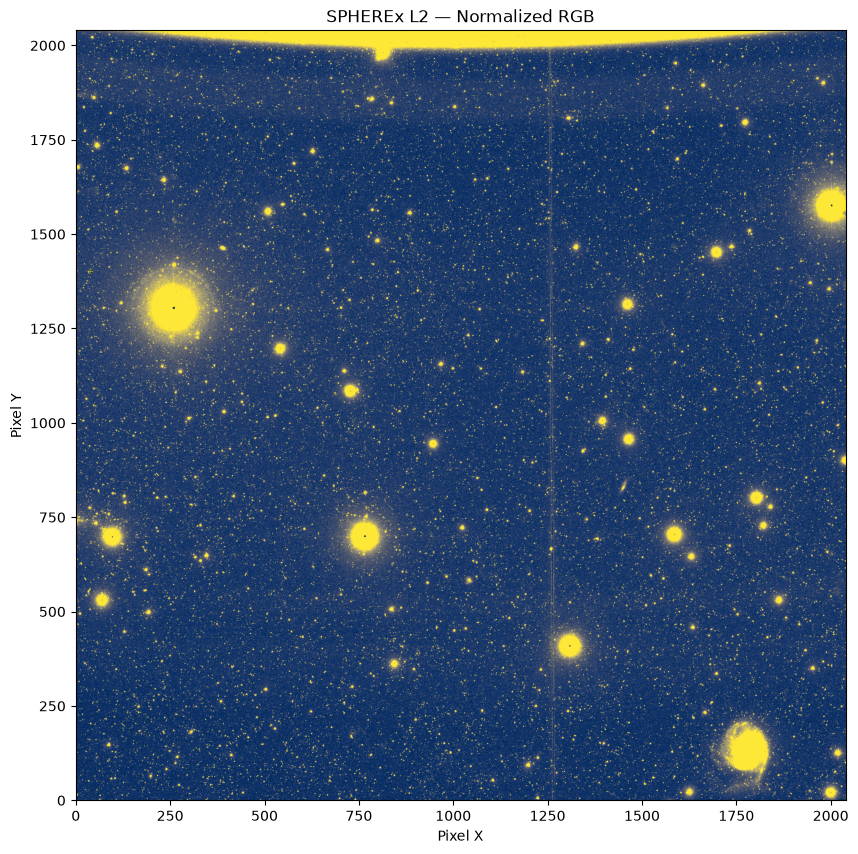

Original shape: (2040, 2040)
RGB shape: (2040, 2040, 3)
RGB range: 0.0 0.995737


In [ ]:

from astropy.io import fits
import matplotlib.pyplot as plt
import numpy as np

url = str(fits_sample)
    
with fits.open(url) as hdul:
    image = hdul["IMAGE"].data.astype(np.float32)

# Mask invalid values
valid = np.isfinite(image)

# Calculate brightness limits
vmin, vmax = np.percentile(image[valid], [3.5, 96.5])

# Normalize brightness to [0, 1]
normalized = np.clip(
    (image - vmin) / max(vmax - vmin, 1e-10),
    0,
    1
)

normalized[~valid] = 0

# Convert normalized values into RGB using a colormap
cmap = plt.get_cmap("cividis")
rgb = cmap(normalized)[..., :3]

# Display RGB image
plt.figure(figsize=(10, 10))
plt.imshow(rgb, origin="lower")
plt.title("SPHEREx L2 — Normalized RGB")
plt.xlabel("Pixel X")
plt.ylabel("Pixel Y")
plt.show()

print("Original shape:", image.shape)
print("RGB shape:", rgb.shape)
print("RGB range:", rgb.min(), rgb.max())


Consultando IRSA...
URLs únicas recuperadas: 2
Procesando [1/2] - Canal SPHEREx-D3
Procesando [2/2] - Canal SPHEREx-D6

¡Cubo de prueba generado! Dimensiones: (2, 2040, 2040)


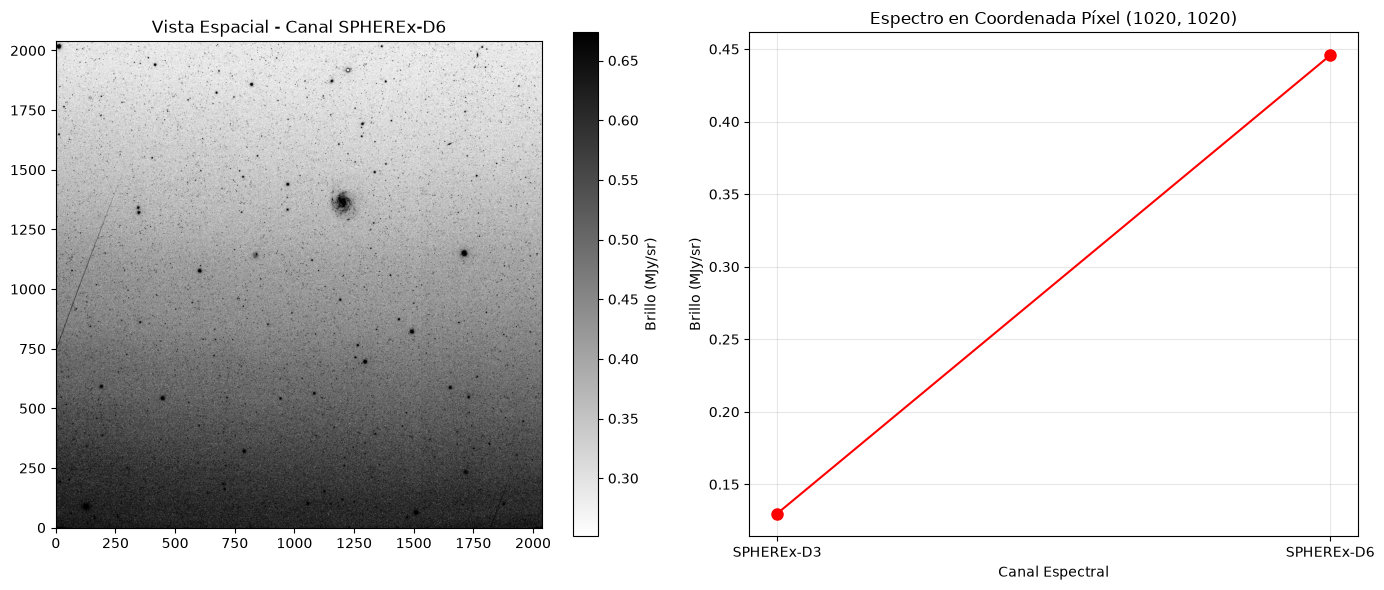

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits
from astroquery.ipac.irsa import Irsa
from astropy.coordinates import SkyCoord
import astropy.units as u

# 1. Definir coordenadas y consultar Astroquery
coord = SkyCoord(ra=210.80227 * u.deg, dec=54.34895 * u.deg, frame="icrs")

print("Consultando IRSA...")
results = Irsa.query_sia(
    pos=(coord, 1 * u.arcsec),
    collection=["spherex_dr1"]
)

results.sort("t_min", reverse=True)
canales_urls = {}
limite_canales = 2  # Límite modificado para pruebas rápidas

# 2. Aislar solo 5 URLs únicas
for row in results:
    canal_id = row["energy_bandpassname"]
    url = row["access_url"]
    
    if canal_id not in canales_urls:
        canales_urls[canal_id] = url
        
    if len(canales_urls) == limite_canales:
        break

print(f"URLs únicas recuperadas: {len(canales_urls)}")

# 3. Leer los FITS directamente y construir el mini-cubo
lista_matrices = []
nombres_canales = sorted(canales_urls.keys())

for i, canal in enumerate(nombres_canales):
    url = canales_urls[canal]
    print(f"Procesando [{i+1}/{limite_canales}] - Canal {canal}")
    
    with fits.open(url, cache=True) as hdul:
        image_data = hdul["IMAGE"].data
        lista_matrices.append(image_data)

cubo_espectral = np.stack(lista_matrices, axis=0)
print(f"\n¡Cubo de prueba generado! Dimensiones: {cubo_espectral.shape}")

# 4. Visualización del Cubo Espectral de Prueba
plt.figure(figsize=(14, 6))

indice_medio = len(nombres_canales) // 2
imagen_corte = cubo_espectral[indice_medio]
valid = imagen_corte[np.isfinite(imagen_corte)]
vmin, vmax = np.percentile(valid, [3.5, 96.5])

plt.subplot(1, 2, 1)
plt.imshow(imagen_corte, cmap="gray_r", origin="lower", vmin=vmin, vmax=vmax)
plt.colorbar(label="Brillo (MJy/sr)")
plt.title(f"Vista Espacial - Canal {nombres_canales[indice_medio]}")

y_centro, x_centro = cubo_espectral.shape[1] // 2, cubo_espectral.shape[2] // 2
espectro_pixel = cubo_espectral[:, y_centro, x_centro]

plt.subplot(1, 2, 2)
# Al ser solo 5 puntos, usamos marcadores más visibles ('o') y etiquetas exactas en el eje X
plt.plot(range(len(nombres_canales)), espectro_pixel, marker='o', color='r', markersize=8)
plt.xticks(range(len(nombres_canales)), nombres_canales)
plt.xlabel("Canal Espectral")
plt.ylabel("Brillo (MJy/sr)")
plt.title(f"Espectro en Coordenada Píxel ({x_centro}, {y_centro})")
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

Text(0.5, 1.0, 'Vista Espacial - Canal SPHEREx-D3')

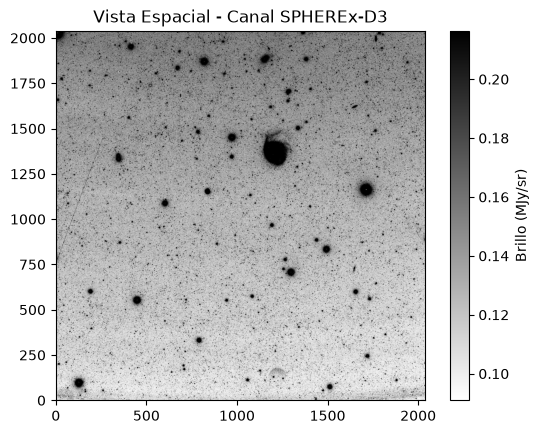

In [5]:
imagen_corte = cubo_espectral[0]
valid = imagen_corte[np.isfinite(imagen_corte)]
vmin, vmax = np.percentile(valid, [3.5, 96.5])

plt.imshow(imagen_corte, cmap="gray_r", origin="lower", vmin=vmin, vmax=vmax)
plt.colorbar(label="Brillo (MJy/sr)")
plt.title(f"Vista Espacial - Canal {nombres_canales[0]}") # Índice 0 manual

Text(0.5, 1.0, 'Vista Espacial - Canal SPHEREx-D6')

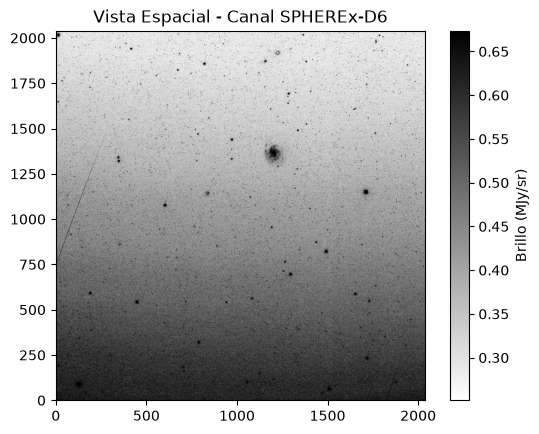

In [6]:
imagen_corte = cubo_espectral[1]
valid = imagen_corte[np.isfinite(imagen_corte)]
vmin, vmax = np.percentile(valid, [3.5, 96.5])

plt.imshow(imagen_corte, cmap="gray_r", origin="lower", vmin=vmin, vmax=vmax)
plt.colorbar(label="Brillo (MJy/sr)")
plt.title(f"Vista Espacial - Canal {nombres_canales[1]}") # Índice 1 manual

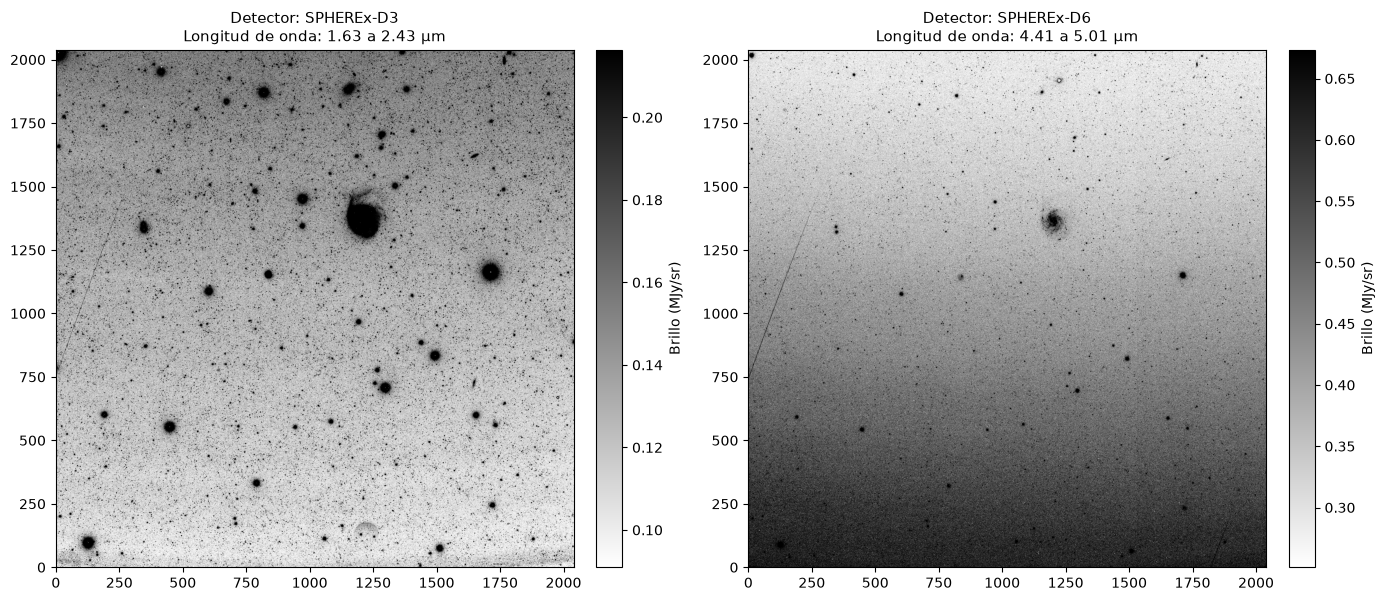

In [7]:
import matplotlib.pyplot as plt
import numpy as np

# Obtenemos la cantidad actual de canales en el cubo
num_canales = len(nombres_canales)
plt.figure(figsize=(7 * num_canales, 6))

for i in range(num_canales):
    canal = nombres_canales[i]
    imagen_corte = cubo_espectral[i]
    
    # --- 1. EXTRACCIÓN DE LA LONGITUD DE ONDA ---
    # Filtramos la tabla de resultados de astroquery para obtener la fila de este detector
    fila_canal = results[results["energy_bandpassname"] == canal][0]
    
    # Extraemos 'em_min' y 'em_max' (en metros) y convertimos a micrómetros (μm)
    if "em_min" in results.colnames and "em_max" in results.colnames:
        wl_min = fila_canal["em_min"] * 1e6
        wl_max = fila_canal["em_max"] * 1e6
        # SPHEREx usa Filtros Variables Lineales (LVF), por lo que captura un "rango" por detector
        texto_onda = f"{wl_min:.2f} a {wl_max:.2f} μm"
    else:
        texto_onda = "Longitud no especificada en metadata"

    # --- 2. CONFIGURACIÓN DE CONTRASTE ---
    valid = imagen_corte[np.isfinite(imagen_corte)]
    vmin, vmax = np.percentile(valid, [3.5, 96.5])
    
    # --- 3. GRAFICADO ---
    plt.subplot(1, num_canales, i + 1)
    plt.imshow(imagen_corte, cmap="gray_r", origin="lower", vmin=vmin, vmax=vmax)
    plt.colorbar(label="Brillo (MJy/sr)", fraction=0.046, pad=0.04)
    
    # Imprimimos el nombre del canal y su longitud de onda captada dinámicamente
    plt.title(f"Detector: {canal}\nLongitud de onda: {texto_onda}", fontsize=11)

plt.tight_layout()
plt.show()